# Matplotlib Exercises — Heart Disease Dataset

These exercises practise the matplotlib techniques from the **Introduction to Matplotlib** notebook, applied to the heart-disease dataset (303 patients).

You'll cover: plotting from a pandas DataFrame, scatter plots coloured by `target`, histograms, subplots (including a shared x-axis), the `over_50` analysis pattern, mean lines (`axhline`), colormaps (`cmap`), axis limits (`xlim`/`ylim`), and saving figures.

**The columns:**

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 0 = female, 1 = male |
| `cp` | Chest pain type (0–3) |
| `trestbps` | Resting blood pressure |
| `chol` | Serum cholesterol (mg/dl) |
| `thalach` | Maximum heart rate achieved |
| `target` | 1 = has heart disease, 0 = no heart disease |

**Instructions:** Solve each exercise in the empty cell below its prompt. Full answers are in the separate notebook **`matplotlib_exercises_solutions.ipynb`** — try each one yourself first.

## 0. Setup

**Exercise 0.** Import `matplotlib.pyplot` as `plt` and `pandas` as `pd`, enable inline plotting, and read `../data/heart-disease.csv` into a DataFrame called `heart_disease`. Show the first 5 rows.

In [1]:
# Your code here
import pandas as pd
import matplotlib.pyplot as plt 

heart_disease = pd.read_csv('../data/heart-disease.csv')
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 1. Plotting directly from a pandas DataFrame

**Exercise 1.** Plot a **histogram** of the `age` column directly from pandas using `.plot.hist()` with 50 bins. What does this tell you about the spread of ages?

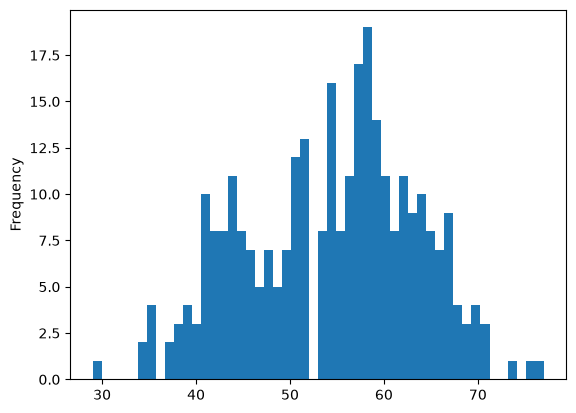

In [6]:
# Your code here
heart_disease['age'].plot.hist(bins=50);

**Exercise 2.** Plot a histogram of **every column at once** by calling `.plot.hist()` on the whole DataFrame with `subplots=True` and `figsize=(5, 20)`.

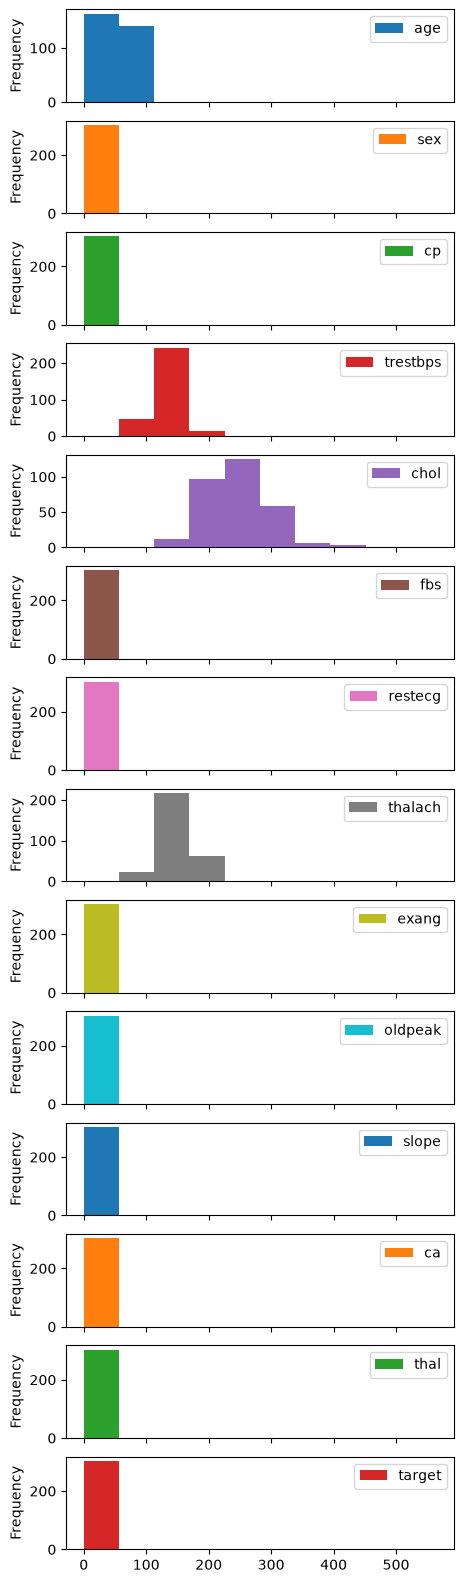

In [ ]:
# Your code here
# 1
# heart_disease.plot(kind='hist', subplots=True, figsize=(5,20));
# 2
heart_disease.plot.hist(subplots=True, figsize=(5,20));

## 2. Analysing patients over 50

**Exercise 3.** Create a new DataFrame called `over_50` containing only the patients **older than 50** (`age > 50`). How many rows does it have?

In [13]:
# Your code here
over_50 = pd.DataFrame(heart_disease[heart_disease['age'] > 50])
over_50.shape

(208, 14)

**Exercise 4.** Using the object-oriented API (`fig, ax = plt.subplots(figsize=(10, 6))`), make a **scatter plot** of `over_50`'s `age` (x) vs `chol` (y), **colouring the points by the `target` column** (`c=over_50["target"]`).

Add a title "Heart Disease and Cholesterol Levels", axis labels, and a legend built with `ax.legend(*scatter.legend_elements(), title="Target")`.

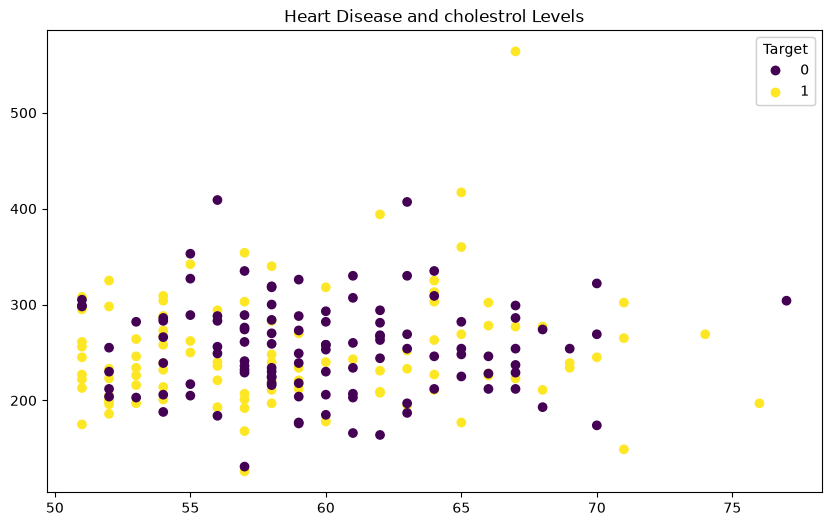

In [23]:
# Your code here
fig, ax = plt.subplots(figsize=(10,6))
scatter = plt.scatter(over_50['age'], over_50['chol'], c=over_50['target'])
plt.title("Heart Disease and cholestrol Levels")
legend = ax.legend(*scatter.legend_elements(), title='Target')
ax.add_artist(legend)


**Exercise 5.** Recreate the scatter plot from Exercise 4, then add a **horizontal dashed line** showing the **mean cholesterol** using `ax.axhline(over_50["chol"].mean(), linestyle="--")`.

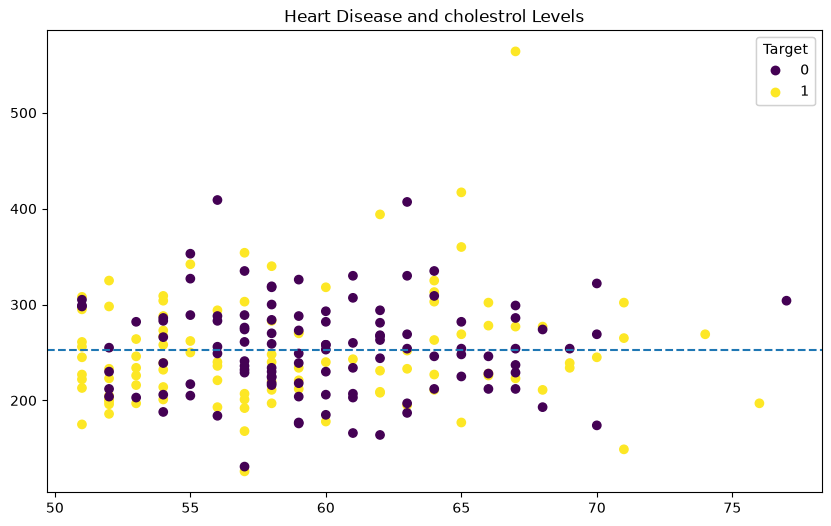

In [24]:
# Your code here
fig, ax = plt.subplots(figsize=(10,6))
scatter = plt.scatter(over_50['age'], over_50['chol'], c=over_50['target'])
plt.title("Heart Disease and cholestrol Levels")
legend = ax.legend(*scatter.legend_elements(), title='Target')
ax.add_artist(legend)
ax.axhline(over_50['chol'].mean(), linestyle="--")

## 3. Multiple Axes on one Figure

**Exercise 6.** Create a Figure with **2 rows and 1 column** of Axes that **share the x-axis** (`nrows=2, ncols=1, sharex=True, figsize=(10, 8)`):

- top Axis (`ax0`): scatter of `over_50` `age` vs `chol`, coloured by `target`
- bottom Axis (`ax1`): scatter of `over_50` `age` vs `thalach`, coloured by `target`

Give each Axis a title and y-label, and a legend.

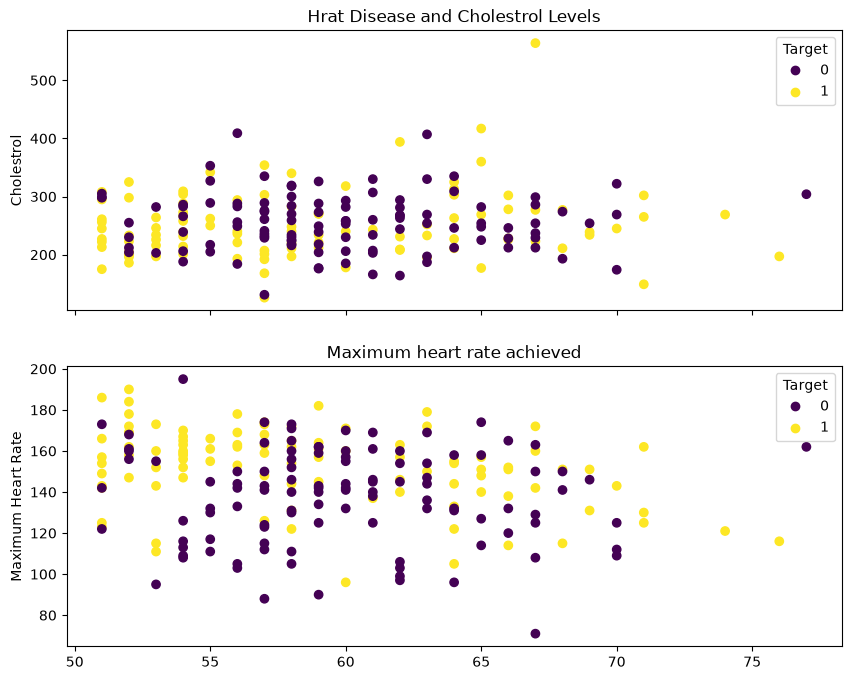

In [37]:
# Your code here
fig, [ax0, ax1] = plt.subplots(2, 1, sharex=True, figsize=(10,8))
scatter0 = ax0.scatter(over_50['age'], over_50['chol'], c=over_50['target'])
ax0.set_title("Hrat Disease and Cholestrol Levels")
ax0.set_ylabel("Cholestrol")
ax0.legend(*scatter0.legend_elements(), title='Target')

scatter1 = ax1.scatter(over_50['age'], over_50['thalach'], c=over_50['target'])
ax1.set_title("Maximum heart rate achieved")
ax1.set_ylabel("Maximum Heart Rate")
ax1.legend(*scatter0.legend_elements(), title='Target')




## 4. Customizing your plots

**Exercise 7.** Redraw the `over_50` `age` vs `chol` scatter, but change the **colormap** to `"winter"` (pass `cmap="winter"` to `ax.scatter`). Add a red mean line with `ax.axhline(..., color="r")`.

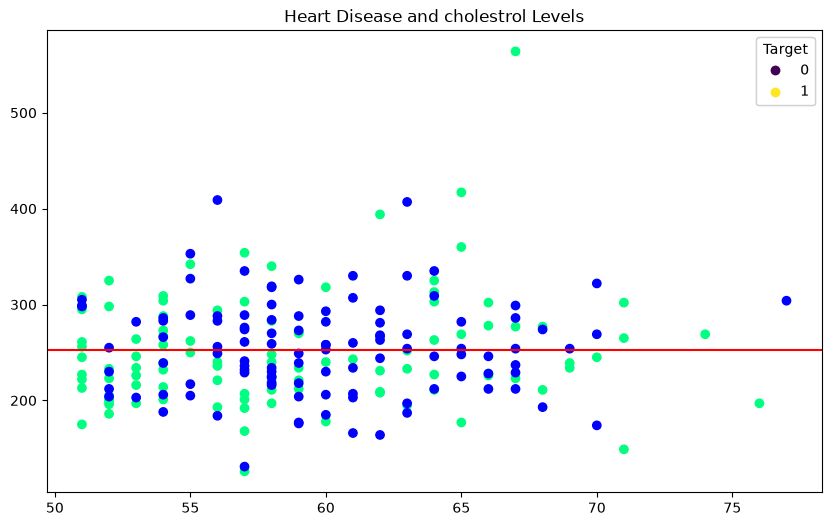

In [ ]:
# Your code here
fig, ax = plt.subplots(figsize=(10,6));
ax.scatter(over_50['age'], over_50['chol'], c=over_50['target'],cmap='winter')
plt.title("Heart Disease and cholestrol Levels")
legend = ax.legend(*scatter.legend_elements(), title='Target')
ax.add_artist(legend)
ax.axhline(over_50['chol'].mean(), color='r')

**Exercise 8.** Redraw the same scatter plot, but set the **axis limits** so the x-axis runs from 50 to 80 and the y-axis from 100 to 600 (use `ax.set(xlim=[50, 80], ylim=[100, 600])`).

[(50.0, 80.0), (100.0, 600.0)]

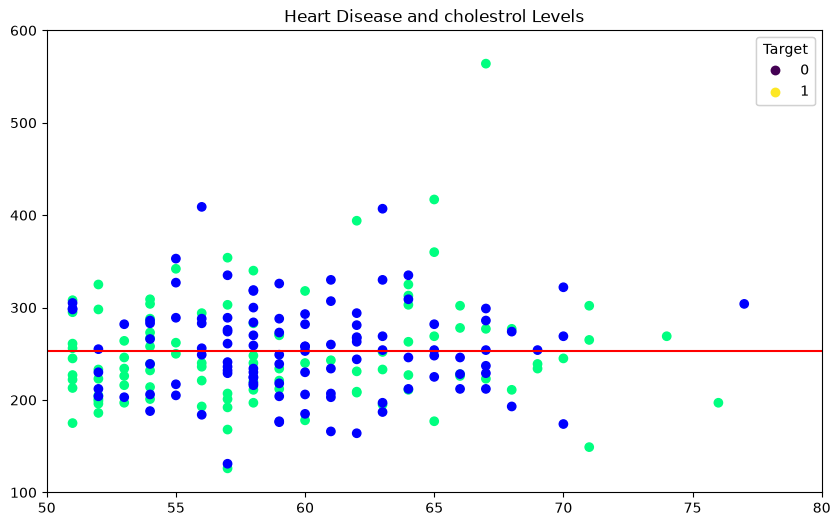

In [43]:
# Your code here
fig, ax = plt.subplots(figsize=(10,6));
ax.scatter(over_50['age'], over_50['chol'], c=over_50['target'],cmap='winter')
plt.title("Heart Disease and cholestrol Levels")
legend = ax.legend(*scatter.legend_elements(), title='Target')
ax.add_artist(legend)
ax.axhline(over_50['chol'].mean(), color='r')
ax.set(xlim=[50,80], ylim=[100,600])


**Exercise 9.** Try a **built-in style**: call `plt.style.use("seaborn-v0_8")` (or `"ggplot"`), then redraw the `age` vs `chol` scatter coloured by `target`. (List options with `plt.style.available`. Reset afterwards with `plt.style.use("default")`.)

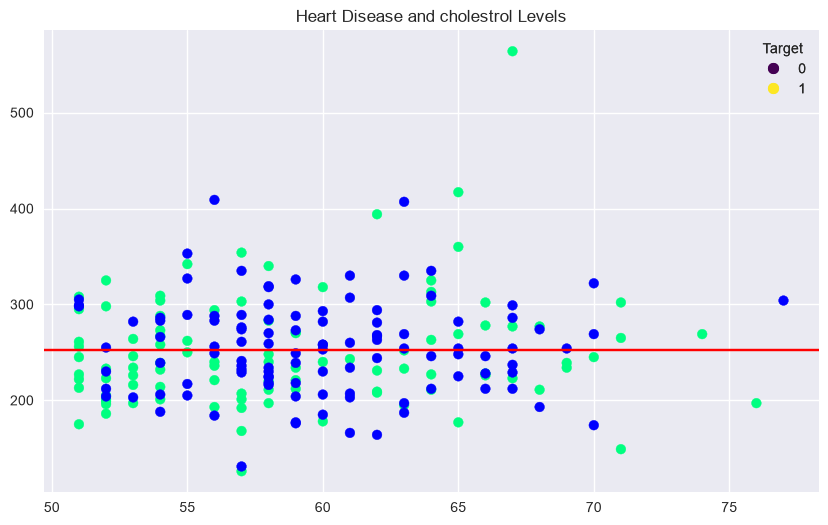

In [45]:
# Your code here
plt.style.use("seaborn-v0_8")
fig, ax = plt.subplots(figsize=(10,6));
ax.scatter(over_50['age'], over_50['chol'], c=over_50['target'],cmap='winter')
plt.title("Heart Disease and cholestrol Levels")
legend = ax.legend(*scatter.legend_elements(), title='Target')
ax.add_artist(legend)
ax.axhline(over_50['chol'].mean(), color='r')

In [47]:
plt.style.use("default")

## 5. Saving plots

**Exercise 10.** Build any plot you like from the data, then **save the figure** to `heart-disease-analysis.png` using `fig.savefig(fname=..., dpi=100)`.

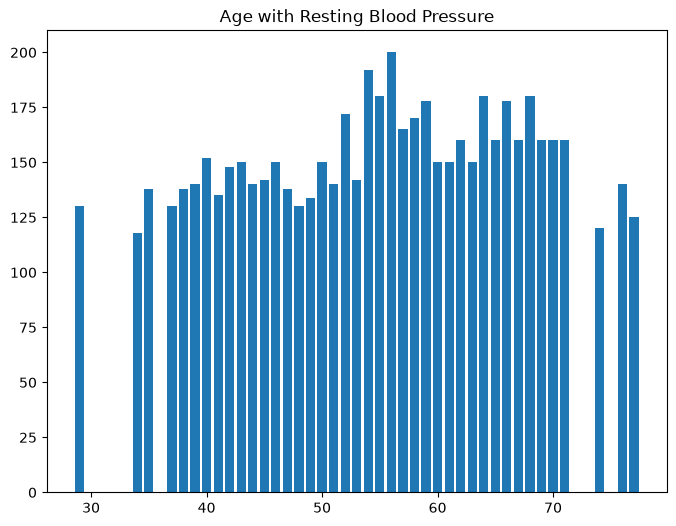

In [52]:
# Your code here
fig, ax = plt.subplots(figsize=(8,6));
ax.bar(heart_disease['age'], heart_disease['trestbps'])
ax.set_title('Age with Resting Blood Pressure')
fig.savefig('heart-disease-analysis.png',dpi=100)

## 🏆 Challenge Exercises

1. Build the **2-row shared-x dashboard** (`age` vs `chol` on top, `age` vs `thalach` below) but use `cmap="winter"` on both, add a **mean line** to each, and set `xlim=[50, 80]`.
2. Add a shared figure title to the dashboard with `fig.suptitle("Heart Disease Analysis (patients over 50)")`.
3. Save the finished dashboard to `heart-disease-analysis.png` with `dpi=100` and `bbox_inches="tight"`.

C:\Users\DELL\AppData\Local\Temp\ipykernel_3316\3239070169.py:4: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax1.scatter(over_50['age'], over_50['chol'], cmap='winter')
C:\Users\DELL\AppData\Local\Temp\ipykernel_3316\3239070169.py:8: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax2.scatter(over_50['age'], over_50['thalach'], cmap='winter')


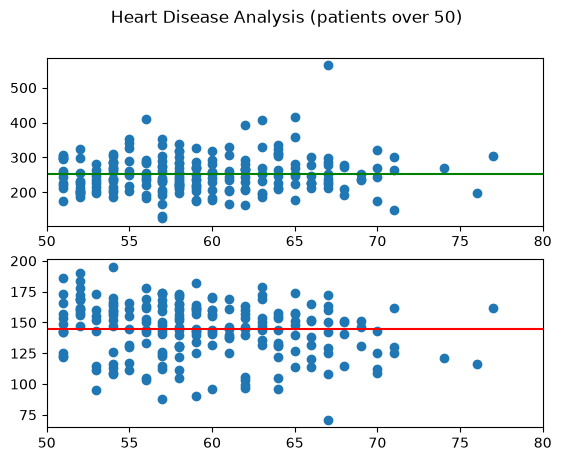

In [59]:
# Your challenge code here
fig, (ax1, ax2) = plt.subplots(2)
fig.suptitle('Heart Disease Analysis (patients over 50)')
ax1.scatter(over_50['age'], over_50['chol'], cmap='winter')
ax1.set_xlim([50, 80])
ax1.axhline(over_50['chol'].mean(), color='g')

ax2.scatter(over_50['age'], over_50['thalach'], cmap='winter')
ax2.set_xlim([50, 80])
ax2.axhline(over_50['thalach'].mean(), color='r')

fig.savefig("heart-disease-analysis.png", dpi=100, bbox_inches='tight')